# Chapter 94: Health Capital, Medical Uncertainty, and Provider Incentives

This notebook reruns four worked examples from the chapter: review before treatment, a premium spiral and reinsurance, depreciation and technology in a health stock, and coinsurance and extra visits. Every number is one of the chapter's hypothetical teaching values in resource units, not clinical or market data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def capital_stock_decay(K, delta, periods=1, investment=0.0):
    """Stock after `periods` of geometric depreciation: K (1 - delta)^periods + investment.

    religious-human-capital-accumulation (chapter 92): 0.9(2) + 3 = 4.8; 4.8(0.9)^3 = 3.50.
    grossman-health-capital-model (chapter 94): 0.8(80) + 8 = 72.
    """
    return K * (1 - delta) ** periods + investment


def review_screening_cost(n_pos, review, removed, procedure):
    """Automatic treatment n_pos x procedure against review of every positive plus remaining procedures.

    arrow-medical-care-uncertainty-principle (chapter 94): 28(20,000) = 560,000; 28(1,000) + 16(20,000)
    = 348,000; saving 212,000.
    """
    auto = n_pos * procedure
    rev = n_pos * review
    treat = (n_pos - removed) * procedure
    return {"auto": auto, "review": rev, "treat": treat, "reviewed": rev + treat, "saving": auto - rev - treat}


def pooled_premium(groups):
    """Break-even premium: sum(n c) / sum(n) for groups given as (n, expected claim).

    health-insurance-adverse-selection-death-spiral (chapter 94): 4,400; 5,428.57; 6,800; 4,285.71.
    """
    n = sum(g[0] for g in groups)
    return sum(g[0] * g[1] for g in groups) / n


def health_next(H, delta, A, M):
    """Grossman stock: investment I = A sqrt(M), H_next = (1 - delta) H + I, maintenance M = (delta H / A)^2.

    grossman-health-capital-model (chapter 94): 4 sqrt(4) = 8, 0.8(80) + 8 = 72; maintenance 4 and 16.
    """
    inv = A * math.sqrt(M)
    return {"I": inv, "H_next": capital_stock_decay(H, delta, 1, inv), "M_maint": (delta * H / A) ** 2,
            "I_maint": delta * H}


def coinsurance_visits(mb, cost, coins, a=6.0, slope=0.02):
    """Visits q = a - slope P_o at P_o = coins x cost; resource gap of visits beyond the efficient count.

    ex-post-moral-hazard-in-health-insurance (chapter 94): P_o = 50 gives 5 visits; visits 3 to 5 cost
    600 and yield 360, a gap of 240; P_o = 100 gives 4, P_o = 200 gives 2.
    """
    p_o = coins * cost
    q = int(round(max(0.0, min(len(mb), a - slope * p_o))))
    q_eff = sum(1 for v in mb if v >= cost)
    extra = mb[q_eff:q]
    return {"P_o": p_o, "q": q, "q_eff": q_eff, "extra_cost": cost * len(extra), "extra_benefit": sum(extra),
            "gap": cost * len(extra) - sum(extra)}


plt.rcParams.update(HOUSE_RC)


labor = SimpleNamespace(capital_stock_decay=capital_stock_decay, review_screening_cost=review_screening_cost, health_next=health_next, coinsurance_visits=coinsurance_visits)


finance = SimpleNamespace(pooled_premium=pooled_premium)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'arrow-medical-care-uncertainty-principle': {'n_pos': 28,
                                              'procedure': 20000,
                                              'review': 1000,
                                              'removed': 12,
                                              'auto': 560000,
                                              'reviewed': 348000,
                                              'saving': 212000,
                                              'review_cheap': 100},
 'health-insurance-adverse-selection-death-spiral': {'n_high': 400,
                                                     'c_high': 8000,
                                                     'c_low': 2000,
                                                     'p0': 4400,
                                                     'p_300': 5429,
                                                     'p_100': 6800,
                                                     'p_0': 8000,
                                                     'c_high_reins': 6000,
                                                     'p_reins': 4286,
                                                     'threshold': 4500},
 'grossman-health-capital-model': {'H': 80,
                                   'delta': 0.1,
                                   'A': 4,
                                   'I_maint': 8,
                                   'M_maint': 4,
                                   'delta_high': 0.2,
                                   'M_maint_high': 16,
                                   'H_next': 72,
                                   'A_high': 8},
 'ex-post-moral-hazard-in-health-insurance': {'cost': 200,
                                              'mb': [300, 240, 180, 120, 60, 20],
                                              'q_none': 2,
                                              'q_25': 5,
                                              'q_50': 4,
                                              'P_o_25': 50,
                                              'extra_cost': 600,
                                              'extra_benefit': 360,
                                              'gap': 240},
 'constructed': {'arrow-medical-care-uncertainty-principle': {'review': [3000], 'removed': [6, 18]},
                 'health-insurance-adverse-selection-death-spiral': {'c_high': [7000]},
                 'grossman-health-capital-model': {'M': [9]},
                 'ex-post-moral-hazard-in-health-insurance': {'coins': [0]}}}


LABEL = "Hypothetical teaching values, not clinical or market data."


def review_picture(rc=1000, fp=12):
    b = BV["arrow-medical-care-uncertainty-principle"]
    r = labor.review_screening_cost(b["n_pos"], rc, fp, b["procedure"])
    fig, ax = new_figure()
    xs = np.arange(2)
    ax.bar(xs, [r["auto"], r["treat"]], color=PALETTE["navy"], width=0.55, label="Procedures")
    ax.bar([1], [r["review"]], bottom=[r["treat"]], color=PALETTE["gold"], width=0.55, label="Reviews")
    label(ax, 0, r["auto"], num(r["auto"], 0), dx=0, dy=4, ha="center", box=False)
    label(ax, 1, r["reviewed"], num(r["reviewed"], 0), dx=0, dy=4, ha="center", box=False)
    ax.set_xticks(xs, ["Treat all 28 positives", "Review, then treat"])
    ax.set_ylim(0, 680000)
    ax.set_ylabel("Total cost (units)")
    ax.set_xlabel("Rule")
    ax.legend(loc="upper right", frameon=False, fontsize=10)
    left = b["n_pos"] - fp
    if r["saving"] > 0:
        verdict = f"review saves {num(r['saving'], 0)}"
    elif r["saving"] < 0:
        verdict = f"review costs {num(-r['saving'], 0)} more than treating everyone"
    else:
        verdict = "the two rules cost the same"
    metrics = {"Automatic treatment": num(r["auto"], 0), "Review cost": num(r["review"], 0),
               "Procedures after review": str(left), "Reviewed total": num(r["reviewed"], 0),
               "Saving": num(r["saving"], 0)}
    steps = [f"Automatic: 28 x 20,000 = {num(r['auto'], 0)}",
             f"Review: 28 x {num(rc, 0)} = {num(r['review'], 0)}; procedures 28 - {fp} = {left}",
             f"Reviewed: {num(r['review'], 0)} + {left} x 20,000 = {num(r['reviewed'], 0)}",
             f"Saving = {num(r['auto'], 0)} - {num(r['reviewed'], 0)} = {num(r['saving'], 0)}"]
    interp = (f"{LABEL} Reviewing each of the 28 positives at {num(rc, 0)} removes "
              f"{plural(fp, 'false positive')}, leaving {left} procedures. The reviewed rule costs "
              f"{num(r['review'], 0)} + {left} x 20,000 = {num(r['reviewed'], 0)} against {num(r['auto'], 0)}, so "
              f"{verdict}. The review addresses hidden clinical quality, not the pooling of expenditure.")
    alt = (f"Two bars: treating all positives costs {num(r['auto'], 0)}; reviewing first costs {num(r['reviewed'], 0)}, "
           f"of which {num(r['review'], 0)} is review.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def spiral_picture(low=300, high=8000):
    b = BV["health-insurance-adverse-selection-death-spiral"]
    p = finance.pooled_premium([(low, b["c_low"]), (b["n_high"], high)])
    fig, ax = new_figure()
    bar_compare(ax, ["Starting premium", "Next premium"], [b["p0"], p],
                colors=["grey", "terracotta" if p > b["threshold"] else "teal"],
                value_labels=[num(b["p0"], 0), num(p, 0)], ylabel="Premium (units)", xlabel="Pool")
    hline(ax, b["threshold"], col="navy")
    ax.set_xlabel("Pool (dashed line: renewal threshold 4,500)")
    ax.set_ylim(0, 9500)
    n = low + b["n_high"]
    if low == 600:
        verdict = ("the pool before anyone leaves. The 4,500 threshold describes only the 300 members who renew in "
                   "the chapter; at 4,400 the other 300 low-risk members already leave")
        if high != 8000:
            verdict += ", and the chapter does not say how they respond to this lower premium"
    elif p > b["threshold"]:
        verdict = "above the 4,500 renewal threshold, so further low-risk exit is predicted"
    elif p < b["threshold"]:
        verdict = "below the 4,500 renewal threshold, so the remaining members renew and the spiral stops"
    else:
        verdict = "exactly at the 4,500 threshold"
    metrics = {"Members": num(n, 0), "Next premium": num(p, 0), "Change from 4,400": f"{p - 4400:+,.0f}",
               "Spiral": ("Starting pool" if low == 600 else ("Continues" if p > b["threshold"] else "Stops"))}
    steps = [f"Claims = {low} x 2,000 + 400 x {num(high, 0)} = {num(low * 2000, 0)} + {num(400 * high, 0)} = "
             f"{num(low * 2000 + 400 * high, 0)}",
             f"Premium = {num(low * 2000 + 400 * high, 0)} / {n} = {num(p, 0)}",
             (f"{num(p, 0)}: starting pool, before the first exit" if low == 600 else
              f"{num(p, 0)} against 4,500: {'above' if p > 4500 else 'below'}")]
    interp = (f"{LABEL} With {low} low-risk members renewing and a high-risk cost of {num(high, 0)}, the break-even "
              f"premium is ({low} x 2,000 + 400 x {num(high, 0)}) / {n} = {num(p, 0)}, {verdict}. Each price "
              f"change alters who stays, which sets the next price.")
    alt = f"Two bars: the starting premium 4,400 and the next premium {num(p, 0)}, with a line at 4,500."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def grossman_picture(delta=0.10, a=4, m=4):
    b = BV["grossman-health-capital-model"]
    r = labor.health_next(b["H"], delta, a, m)
    fig, ax = new_figure()
    bar_compare(ax, ["Health now H_t", "Next period H_t+1"], [b["H"], r["H_next"]],
                colors=["grey", "teal" if r["H_next"] >= b["H"] else "terracotta"],
                value_labels=[num(b["H"], 0), num(r["H_next"])], ylabel="Health stock", xlabel="Period")
    hline(ax, b["H"], col="navy")
    ax.set_xlabel("Period (dashed line: maintenance level 80)")
    ax.set_ylim(0, 110)
    change = r["H_next"] - b["H"]
    if change > 0:
        verdict = f"health rises by {num(change)}"
    elif change < 0:
        verdict = f"health falls by {num(-change)}"
    else:
        verdict = "health is maintained exactly"
    metrics = {"Investment I": num(r["I"]), "Next-period health": num(r["H_next"]),
               "Required investment": num(r["I_maint"]), "Maintenance M": num(r["M_maint"])}
    steps = [f"I = {a} x sqrt({m}) = {num(r['I'])}",
             f"H_t+1 = {num(1 - delta)} x 80 + {num(r['I'])} = {num((1 - delta) * 80)} + {num(r['I'])} = "
             f"{num(r['H_next'])}",
             f"Maintenance: {a} sqrt(M) = {num(delta)} x 80 = {num(r['I_maint'])}, so M = "
             f"({num(r['I_maint'])} / {a})^2 = {num(r['M_maint'])}"]
    interp = (f"{LABEL} With depreciation delta = {num(delta)}, technology I = {a} sqrt(M) and medical input "
              f"{m} hundred, investment is {num(r['I'])} and next-period health is {num(1 - delta)} x 80 + "
              f"{num(r['I'])} = {num(r['H_next'])}: {verdict}. Holding health at 80 needs M = {num(r['M_maint'])}.")
    alt = f"Two bars: health 80 now and {num(r['H_next'])} next period, with a line at 80."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def coinsurance_picture(co=0.25):
    b = BV["ex-post-moral-hazard-in-health-insurance"]
    mb, cost = b["mb"], b["cost"]
    r = labor.coinsurance_visits(mb, cost, co)
    fig, ax = new_figure()
    units = np.arange(1, len(mb) + 1)
    cols = [PALETTE["teal"] if u <= r["q_eff"] else (PALETTE["terracotta"] if u <= r["q"] else PALETTE["grey"])
            for u in units]
    ax.bar(units, mb, color=cols, width=0.7)
    for u, v in zip(units, mb):
        label(ax, u, v, num(v, 0), dx=0, dy=3, ha="center", box=False)
    hline(ax, cost, "resource cost 200", col="navy", style="solid", x_frac=0.62)
    if r["P_o"] != cost:
        hline(ax, r["P_o"], f"out-of-pocket price {num(r['P_o'], 0)}", col="gold", x_frac=0.02)
    ax.set_xticks(units)
    ax.set_ylim(0, 340)
    ax.set_xlabel("Visit number (red: used but worth less than 200)")
    ax.set_ylabel("Marginal benefit (units)")
    extra = r["q"] - r["q_eff"]
    metrics = {"Out-of-pocket price P_o": num(r["P_o"], 0), "Visits q": str(r["q"]),
               "Visits beyond efficient": str(extra), "Resource gap": num(r["gap"], 0)}
    steps = [f"P_o = {num(co)} x 200 = {num(r['P_o'], 0)}",
             f"q = 6 - 0.02 x {num(r['P_o'], 0)} = {r['q']}"]
    if extra:
        used = " + ".join(num(v, 0) for v in mb[r["q_eff"]:r["q"]])
        steps.append(f"Extra visits cost {extra} x 200 = {num(r['extra_cost'], 0)} and yield {used} = "
                     f"{num(r['extra_benefit'], 0)}")
        steps.append(f"Gap = {num(r['extra_cost'], 0)} - {num(r['extra_benefit'], 0)} = {num(r['gap'], 0)}")
    else:
        steps.append("No visit worth less than 200 is used, so the resource gap is 0")
    interp = (f"{LABEL} At {num(100 * co, 0)} percent coinsurance the patient pays {num(r['P_o'], 0)} per visit and "
              f"demand is 6 - 0.02 x {num(r['P_o'], 0)} = {plural(r['q'], 'visit')}. Only the first 2 are worth their "
              f"200 resource cost, so {plural(extra, 'extra visit')} "
              + (f"cost {num(r['extra_cost'], 0)} and yield {num(r['extra_benefit'], 0)}, a gap of {num(r['gap'], 0)}."
                 if extra else "are used and there is no gap.")
              + " The gap is not the whole welfare effect, because insurance also protects against an uncertain bill.")
    alt = (f"Six bars of marginal benefit (300 down to 20) with a line at the resource cost 200 and the "
           f"out-of-pocket price {num(r['P_o'], 0)}; {r['q']} visits are used.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Arrow medical-care uncertainty: review before treatment

Hypothetical values: 28 positives (10 sick, 18 healthy), a 20,000 procedure and a review that removes 12 false positives.

$$28(20{,}000)=560{,}000, \qquad 28(1{,}000)+16(20{,}000)=348{,}000$$

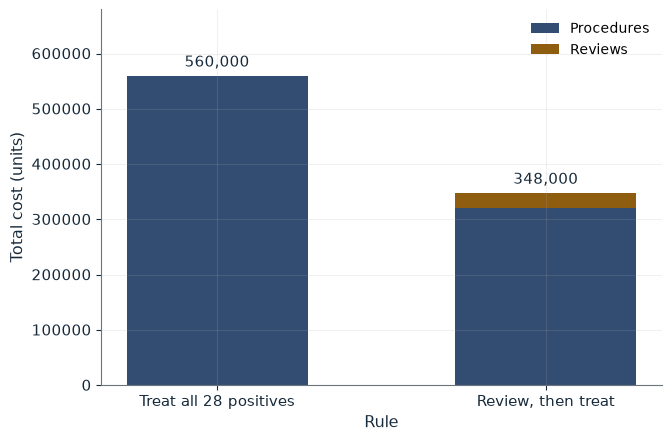

Automatic treatment      560,000
Review cost              28,000
Procedures after review  16
Reviewed total           348,000
Saving                   212,000

Worked steps:
  1. Automatic: 28 x 20,000 = 560,000
  2. Review: 28 x 1,000 = 28,000; procedures 28 - 12 = 16
  3. Reviewed: 28,000 + 16 x 20,000 = 348,000
  4. Saving = 560,000 - 348,000 = 212,000

Hypothetical teaching values, not clinical or market data. Reviewing each of the 28 positives at 1,000 removes 12 false positives, leaving 16 procedures. The reviewed rule costs 28,000 + 16 x 20,000 = 348,000 against 560,000, so review saves 212,000. The review addresses hidden clinical quality, not the pooling of expenditure.


In [2]:
show(review_picture(rc=1000, fp=12))

Change one input, `rc`, and hold the others at the book's values:

In [3]:
sweep(review_picture, 'rc', [100, 1000, 3000], {'fp': 12}, ['Reviewed total', 'Saving'])

rc | Reviewed total | Saving
100 | 322,800 | 237,200
1000 | 348,000 | 212,000
3000 | 404,000 | 156,000


Review at 1,000 a case saves 212,000; even at 3,000 a case it saves 156,000.

## 2. Health-insurance death spiral: the premium spiral

Hypothetical values: 400 high-risk members at 8,000 and low-risk members at 2,000; low-risk members renew only below 4,500.

$$\frac{600(2{,}000)+400(8{,}000)}{1{,}000}=4{,}400$$

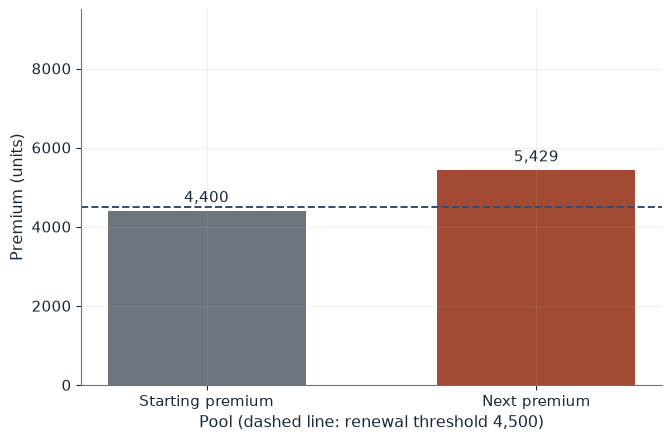

Members            700
Next premium       5,429
Change from 4,400  +1,029
Spiral             Continues

Worked steps:
  1. Claims = 300 x 2,000 + 400 x 8,000 = 600,000 + 3,200,000 = 3,800,000
  2. Premium = 3,800,000 / 700 = 5,429
  3. 5,429 against 4,500: above

Hypothetical teaching values, not clinical or market data. With 300 low-risk members renewing and a high-risk cost of 8,000, the break-even premium is (300 x 2,000 + 400 x 8,000) / 700 = 5,429, above the 4,500 renewal threshold, so further low-risk exit is predicted. Each price change alters who stays, which sets the next price.


In [4]:
show(spiral_picture(low=300, high=8000))

Change one input, `low`, and hold the others at the book's values:

In [5]:
sweep(spiral_picture, 'low', [600, 300, 100], {'high': 8000}, ['Next premium', 'Spiral'])

low | Next premium | Spiral
600 | 4,400 | Starting pool
300 | 5,429 | Continues
100 | 6,800 | Continues


With 300 renewals the premium jumps to 5,429 and with 100 to 6,800. Reinsurance at 6,000 brings the 300-member premium to 4,286, below the threshold.

## 3. Grossman health capital: depreciation, technology and spending

Hypothetical values: health 80, investment I = A sqrt(M) with M in hundreds. The chapter's inline text writes delta = 0.10 without the TeX backslash; the value is 0.10.

$$I=4\sqrt{M}, \qquad H_{t+1}=0.8(80)+8=72$$

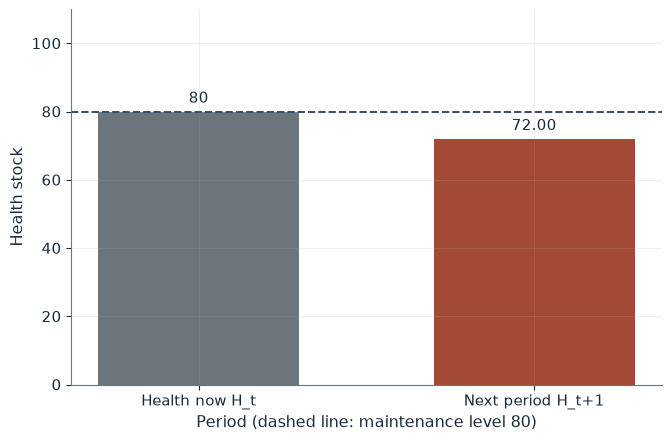

Investment I         8.00
Next-period health   72.00
Required investment  16.00
Maintenance M        16.00

Worked steps:
  1. I = 4 x sqrt(4) = 8.00
  2. H_t+1 = 0.80 x 80 + 8.00 = 64.00 + 8.00 = 72.00
  3. Maintenance: 4 sqrt(M) = 0.20 x 80 = 16.00, so M = (16.00 / 4)^2 = 16.00

Hypothetical teaching values, not clinical or market data. With depreciation delta = 0.20, technology I = 4 sqrt(M) and medical input 4 hundred, investment is 8.00 and next-period health is 0.80 x 80 + 8.00 = 72.00: health falls by 8.00. Holding health at 80 needs M = 16.00.


In [6]:
show(grossman_picture(delta=0.20, a=4, m=4))

Change one input, `m`, and hold the others at the book's values:

In [7]:
sweep(grossman_picture, 'm', [4, 9, 16], {'delta': 0.2, 'a': 4}, ['Next-period health', 'Maintenance M'])

m | Next-period health | Maintenance M
4 | 72.00 | 16.00
9 | 76.00 | 16.00
16 | 80.00 | 16.00


At 20 percent depreciation, spending 4 leaves health at 72 and maintenance needs M = 16. Doubling technology (A = 8) restores maintenance at M = 4.

## 4. Ex-post moral hazard: coinsurance and extra visits

Hypothetical values: visits cost 200 and have marginal benefits 300, 240, 180, 120, 60 and 20.

$$q=6-0.02P_o$$

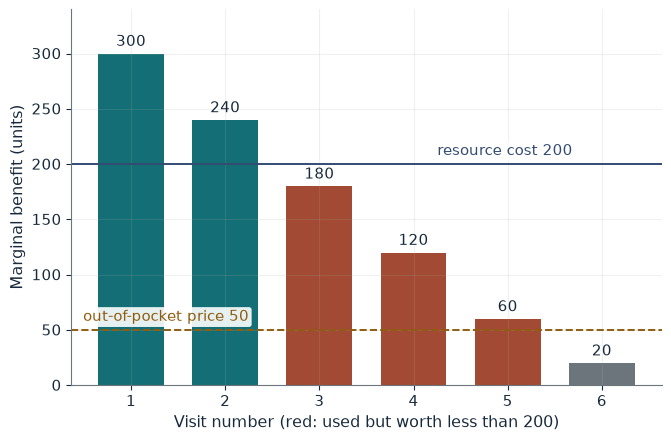

Out-of-pocket price P_o  50
Visits q                 5
Visits beyond efficient  3
Resource gap             240

Worked steps:
  1. P_o = 0.25 x 200 = 50
  2. q = 6 - 0.02 x 50 = 5
  3. Extra visits cost 3 x 200 = 600 and yield 180 + 120 + 60 = 360
  4. Gap = 600 - 360 = 240

Hypothetical teaching values, not clinical or market data. At 25 percent coinsurance the patient pays 50 per visit and demand is 6 - 0.02 x 50 = 5 visits. Only the first 2 are worth their 200 resource cost, so 3 extra visits cost 600 and yield 360, a gap of 240. The gap is not the whole welfare effect, because insurance also protects against an uncertain bill.


In [8]:
show(coinsurance_picture(co=0.25))

Change one input, `co`, and hold the others at the book's values:

In [9]:
sweep(coinsurance_picture, 'co', [0, 0.25, 0.5, 1.0], {}, ['Visits q', 'Resource gap'])

co | Visits q | Resource gap
0 | 6 | 420
0.25 | 5 | 240
0.5 | 4 | 100
1.0 | 2 | 0


At 25 percent coinsurance the patient uses 5 visits; visits 3 to 5 cost 600 and yield 360, a gap of 240. At 50 percent one visit drops out; with no insurance only the 2 efficient visits remain.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

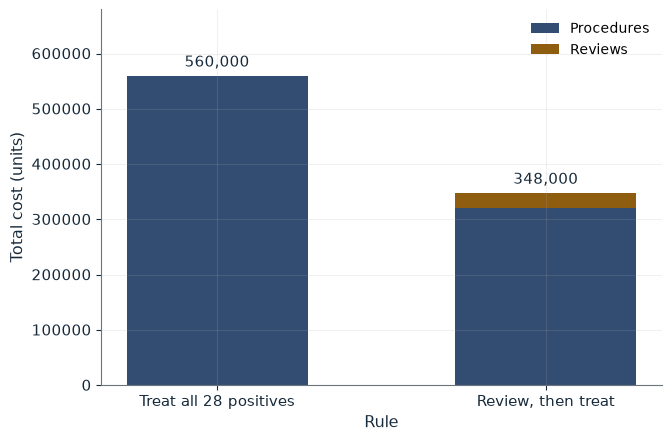

Automatic treatment      560,000
Review cost              28,000
Procedures after review  16
Reviewed total           348,000
Saving                   212,000

Worked steps:
  1. Automatic: 28 x 20,000 = 560,000
  2. Review: 28 x 1,000 = 28,000; procedures 28 - 12 = 16
  3. Reviewed: 28,000 + 16 x 20,000 = 348,000
  4. Saving = 560,000 - 348,000 = 212,000

Hypothetical teaching values, not clinical or market data. Reviewing each of the 28 positives at 1,000 removes 12 false positives, leaving 16 procedures. The reviewed rule costs 28,000 + 16 x 20,000 = 348,000 against 560,000, so review saves 212,000. The review addresses hidden clinical quality, not the pooling of expenditure.


In [10]:
show(review_picture(rc=1000, fp=12))

## Practice

**1.** At a review cost of 3,000 removing 6 false positives, what is the total cost?

<details><summary>Answer</summary>

28 x 3,000 + 22 x 20,000 = 84,000 + 440,000 = 524,000, a saving of 36,000.

</details>

**2.** With 300 renewals and a high-risk cost of 7,000, what is the premium?

<details><summary>Answer</summary>

(600,000 + 2,800,000) / 700 = 4,857, above 4,500.

</details>

**3.** With full insurance, how many visits and what resource gap?

<details><summary>Answer</summary>

q = 6; visits 3 to 6 cost 800 and yield 380, a gap of 420.

</details>